In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import json
import os
import sys
import tensorflow as tf
import tensorflow_probability as tfp
import matplotlib.pyplot as plt

from utils.pyfunctions import *

2026-05-11 15:15:30.779190: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-11 15:15:30.790806: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778534130.799769  127972 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778534130.802826  127972 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-05-11 15:15:30.814092: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
# load results from checkpoint
output_dir = './hmc_results/'
hmc_checkpoint = np.load(output_dir + 'first_check.npz')
samples = hmc_checkpoint['samples']

num_results = samples.shape[0]
n_chains = samples.shape[1]
n_params = samples.shape[2]

In [2]:
# Load final results
output_dir = './hmc_results/'
samp = pd.read_csv(output_dir + 'posterior_samples.csv')
diagnostics = np.load(output_dir + 'diagnostics.npz')

n_chains = 30
n_params = samp.shape[1]
num_results = len(samp) // n_chains

samples = samp.to_numpy().reshape(num_results, n_chains, n_params)

### Check ESS
##### ESS tells you how many independent samples you effectively have for each parameter.
##### a reasonable value should be 10-50% of nchains*nresults, 
##### this means the parameter was well sampled and the posterior is robust, low values mean that there was very high autocorrelation and you maybe didn't sample well, increase jump size or allow auto tuning. 

In [3]:
# reshape because this was saved weird:
samples_tf = tf.constant(samples, dtype=tf.float64)

#samples_reshaped = tf.reshape(samples_tf, [n_chains, num_results, -1])

ess = tfp.mcmc.effective_sample_size(samples_tf)  # (n_chains, 236)
ess_total = tf.reduce_sum(ess, axis=0)  # (236,)

2026-05-11 15:37:23.984696: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [ ]:
ess_byChain = tfp.mcmc.effective_sample_size(samples_tf).numpy()
ess = ess_byChain.sum(axis=0)
print(f"ESS     (min/median/max): {ess.min():.0f} / {np.median(ess):.0f} / {ess.max():.0f}")

rhat = tfp.mcmc.potential_scale_reduction(samples_tf).numpy()
print(f"R-hat   (min/median/max): {rhat.min():.4f} / {np.median(rhat):.4f} / {rhat.max():.4f}")

### Check r-hat

In [7]:
samples_reshaped = tf.reshape(samples_tf, [num_results,n_chains, -1])
rhat = tfp.mcmc.potential_scale_reduction(samples_reshaped)

Text(0, 0.5, 'n_params')

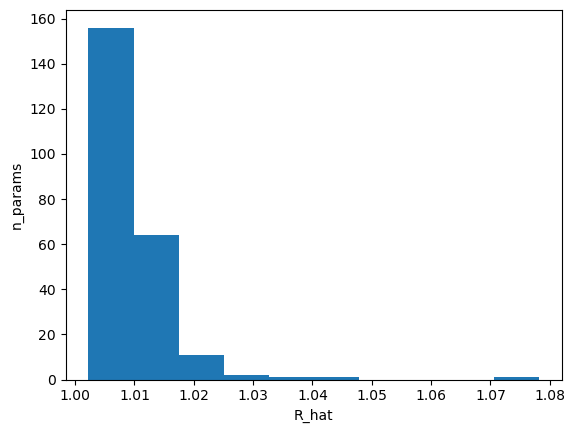

In [8]:
plt.hist(rhat)
plt.xlabel('R_hat')
plt.ylabel('n_params')

In [9]:
# Any problematic parameters?
bad_params = np.where(rhat > 1.05)[0]
print(f"\nParameters with R-hat > 1.05: {len(bad_params)}")

if len(bad_params) > 0:
    param_names = samp.columns.tolist()
    for i in bad_params:
        print(f"  {param_names[i]}: {rhat[i]:.4f}")


Parameters with R-hat > 1.05: 1
  ACCLIM_SF: 1.0782


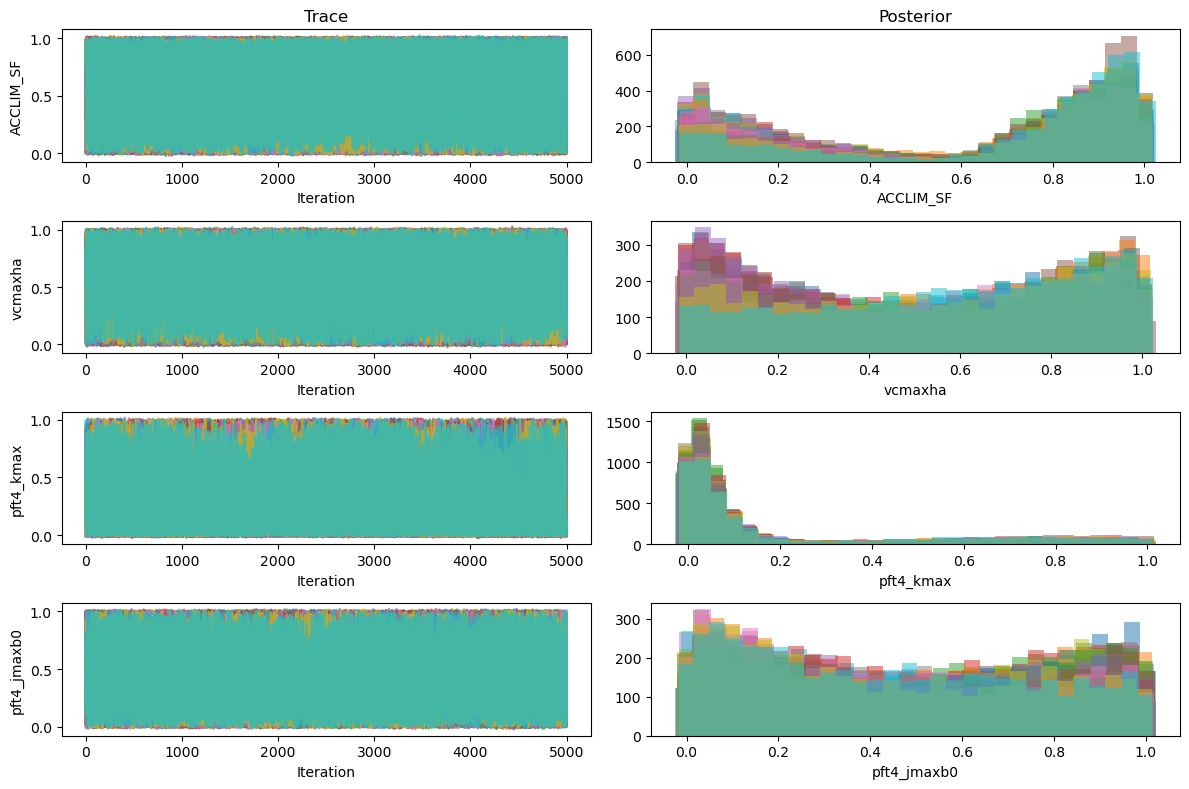

In [14]:
# Reshape to (n_chains, num_results, n_params)
samples_array = samples.reshape(n_chains, num_results, -1)
param_names = samp.columns.tolist()

# Plot traces for a few parameters
def plot_traces(param_indices, figsize=(12, 8)):
    n_params = len(param_indices)
    fig, axes = plt.subplots(n_params, 2, figsize=figsize)
    
    for i, idx in enumerate(param_indices):
        # Trace plot (left)
        for chain in range(n_chains):
            axes[i, 0].plot(samples_array[chain, :, idx], alpha=0.7)
        axes[i, 0].set_ylabel(param_names[idx])
        axes[i, 0].set_xlabel('Iteration')
        
        # Histogram (right)
        for chain in range(n_chains):
            axes[i, 1].hist(samples_array[chain, :, idx], bins=30, alpha=0.5)
        axes[i, 1].set_xlabel(param_names[idx])
    
    axes[0, 0].set_title('Trace')
    axes[0, 1].set_title('Posterior')
    plt.tight_layout()
    return fig

# Plot first 5 parameters
fig = plot_traces([10,6,86,88])
plt.savefig(output_dir + 'traces.png', dpi=150)

### Select from the posterior

In [21]:
# Thin to approximately independent samples
thin_factor = len(samples) // 1000
thinned = samples.iloc[::thin_factor] 

# Then randomly sample from thinned set
idx = np.random.choice(len(thinned), 200, replace=False)
ensemble = thinned.iloc[idx]
ensemble_clipped = ensemble.clip(0, 1)

In [22]:
ensemble_clipped.to_csv(output_dir+'selected_posterior_subset.csv')

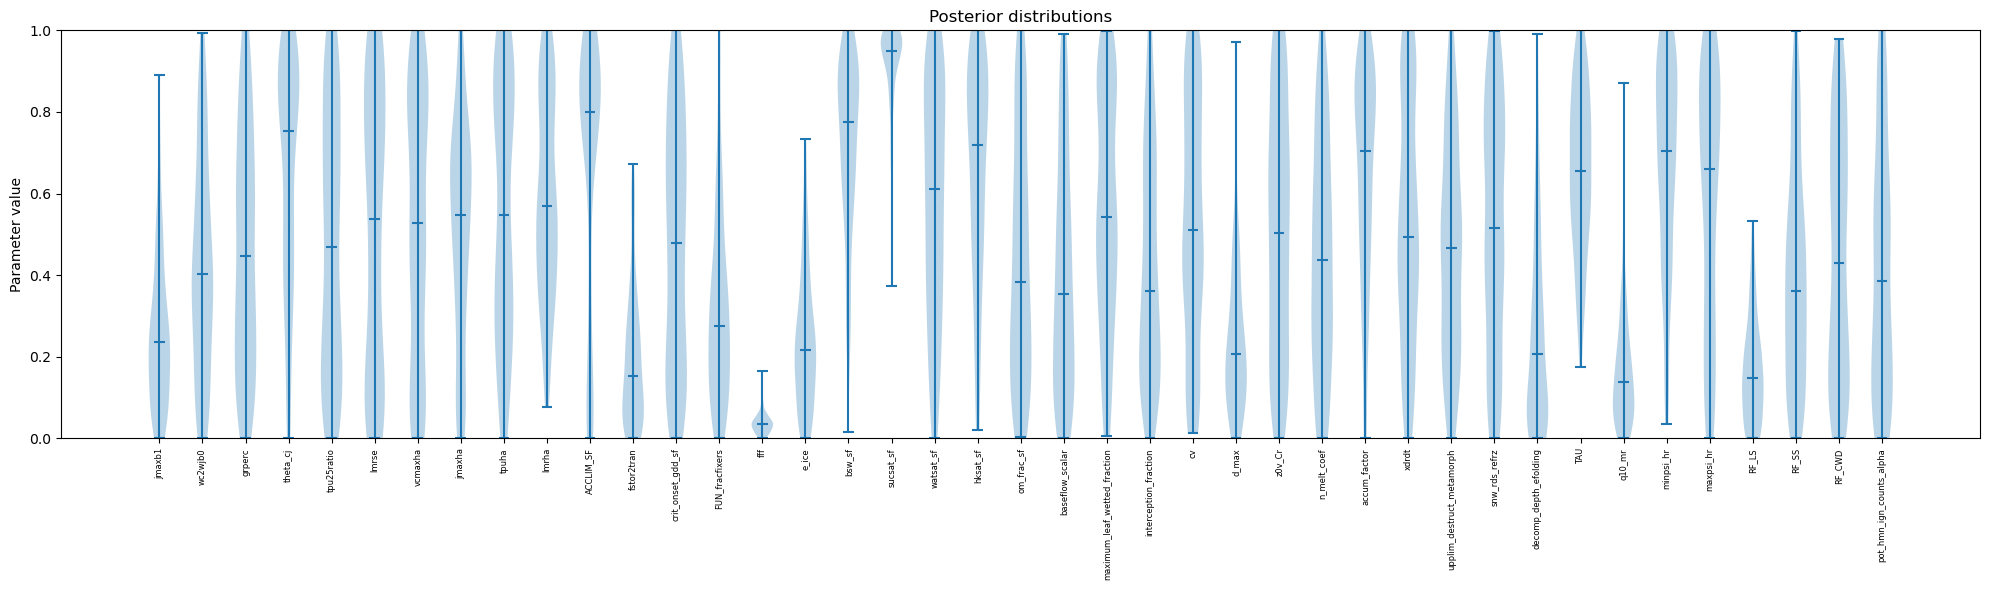

In [43]:
# plot universal parameter posteriors
fig, ax = plt.subplots(figsize=(20, 6))

ax.violinplot(ensemble_clipped.iloc[:, :41].values, showmedians=True)

ax.set_xticks(range(1, len(samples.iloc[:, :41].columns) + 1))
ax.set_xticklabels(samples.iloc[:, :41].columns, rotation=90, fontsize=6)
ax.set_ylabel('Parameter value')
ax.set_ylim(0, 1)
ax.set_title('Posterior distributions')

plt.tight_layout()
plt.savefig(output_dir + 'posteriors_universals_selected200.png', dpi=150)

### Save samples as netcdf

In [39]:
utils_dir = '../utils/'
from utils.hm_pyfunctions import *

In [40]:
# save the sample as a netCDF (param values are still normalized)
default_params = xr.open_dataset(utils_dir+'/default_params_norm.nc')
param_ranges='../gen_ensembles/gen_paramfiles/clm6ppe_paramranges_10042025.csv'
paramset_csv = output_dir+'selected_posterior_subset.csv'
outfile = output_dir+'selected_posterior_subset.nc'

In [42]:
write_paramset_ds(default_params, param_ranges, paramset_csv, pft_param_names, outfile)